# Lab01: Regression — Ước lượng PM2.5 theo ngày tại TP.HCM

Code lấy nguyên từ bài **Lab01 — Python cho Máy học** (`Lab01_hoan_chinh.ipynb`, dự đoán giá nhà AmesHousing),
**chỉ đổi dữ liệu đầu vào**: thay `AmesHousing.txt` bằng số liệu không khí của đồ án AirHCM.

| Bài Lab gốc | Bản này |
|---|---|
| 1 dòng = 1 căn nhà | 1 dòng = 1 ngày ở TP.HCM (08/2022 → 10/2026) |
| Mục tiêu `SalePrice` | Mục tiêu `pm2_5` (µg/m³, trung bình ngày) |
| `Overall Qual`, `Gr Liv Area`, `Total Bsmt SF`, `Overall Cond` | nhiệt độ, độ ẩm, gió, mưa, áp suất |
| `Central Air` (Y/N) | `mua` (Y = mùa mưa, N = mùa khô) |

> PM2.5 ở đây là số liệu **mô hình CAMS** (độ phân giải ~45 km), chưa phải số đo trạm mặt đất.

## Linear Regression
### Khai báo sử dụng thư viện

In [1]:
# ===== BƯỚC CHUẨN BỊ (ô duy nhất được thêm vào so với bài Lab) =====
# Đổi dữ liệu đầu vào sang dữ liệu không khí TP.HCM của đồ án AirHCM.
# Nguồn: du_lieu/gio_cache.csv — Open-Meteo, số liệu THEO GIỜ tại trung tâm TP.HCM (10.7769, 106.7009):
#   PM2.5, PM10 (mô hình CAMS) + nhiệt độ, độ ẩm, gió, mưa, áp suất (ERA5).
# Gộp thành số liệu THEO NGÀY (mỗi dòng = 1 ngày) rồi lưu ./data/pm25_hcm_ngay.csv.
from pathlib import Path
import numpy as np
import pandas as pd

goc = Path.cwd()
while not (goc / 'du_lieu' / 'gio_cache.csv').exists() and goc.parent != goc:
    goc = goc.parent
gio = pd.read_csv(goc / 'du_lieu' / 'gio_cache.csv', parse_dates=['time'])

ngay = gio.set_index('time').resample('D').agg({
    'pm2_5': 'mean', 'pm10': 'mean',
    'temperature_2m': 'mean', 'relative_humidity_2m': 'mean', 'wind_speed_10m': 'mean',
    'precipitation': 'sum', 'surface_pressure': 'mean',
})
ngay = ngay.interpolate(limit=3).dropna()           # vài giờ đầu chuỗi CAMS bị thiếu
ngay['mua'] = np.where(ngay.index.month.isin(range(5, 12)), 'Y', 'N')   # Y = mùa mưa (5–11), N = mùa khô
ngay.index.name = 'date'

Path('data').mkdir(exist_ok=True)
ngay.round(2).to_csv('data/pm25_hcm_ngay.csv')
print(ngay.shape, ngay.index.min().date(), '→', ngay.index.max().date())
ngay.head()

(1529, 8) 2022-08-04 → 2026-10-10


,pm2_5,pm10,temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation,surface_pressure,mua
date,,,,,,,,
2022-08-04,22.682353,32.817647,26.916667,86.208333,7.033333,10.4,1006.875000,Y
2022-08-05,18.570833,26.891667,26.987500,85.458333,9.566667,10.6,1006.341667,Y
2022-08-06,18.629167,27.033333,25.925000,87.958333,9.070833,12.2,1005.979167,Y
2022-08-07,20.250000,29.616667,26.287500,87.125000,12.050000,23.0,1005.650000,Y
2022-08-08,24.429167,35.541667,25.629167,87.291667,9.866667,19.1,1005.912500,Y


In [2]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import LabelEncoder, PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from mlxtend.plotting import scatterplotmatrix, heatmap
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor, AdaBoostRegressor
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid')

## 1.1 Đọc dữ liệu

In [3]:
df = pd.read_csv('data/pm25_hcm_ngay.csv')
print(df.shape)
df.head()

(1529, 9)


,date,pm2_5,pm10,temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation,surface_pressure,mua
0,2022-08-04,22.68,32.82,26.92,86.21,7.03,10.4,1006.88,Y
1,2022-08-05,18.57,26.89,26.99,85.46,9.57,10.6,1006.34,Y
2,2022-08-06,18.63,27.03,25.92,87.96,9.07,12.2,1005.98,Y
3,2022-08-07,20.25,29.62,26.29,87.12,12.05,23.0,1005.65,Y
4,2022-08-08,24.43,35.54,25.63,87.29,9.87,19.1,1005.91,Y


In [4]:
cols = ['temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'mua', 'precipitation', 'surface_pressure', 'pm2_5']
df = pd.read_csv('data/pm25_hcm_ngay.csv', usecols=cols)
df.head()

,pm2_5,temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation,surface_pressure,mua
0,22.68,26.92,86.21,7.03,10.4,1006.88,Y
1,18.57,26.99,85.46,9.57,10.6,1006.34,Y
2,18.63,25.92,87.96,9.07,12.2,1005.98,Y
3,20.25,26.29,87.12,12.05,23.0,1005.65,Y
4,24.43,25.63,87.29,9.87,19.1,1005.91,Y


**Ý nghĩa các cột được chọn**

| Cột | Ý nghĩa | Kiểu |
|---|---|---|
| `temperature_2m` | Nhiệt độ trung bình ngày ở độ cao 2 m (°C) | Liên tục |
| `relative_humidity_2m` | Độ ẩm tương đối trung bình ngày (%) | Liên tục |
| `wind_speed_10m` | Tốc độ gió trung bình ngày ở độ cao 10 m (km/h) | Liên tục |
| `precipitation` | Tổng lượng mưa trong ngày (mm) | Liên tục |
| `surface_pressure` | Áp suất bề mặt trung bình ngày (hPa) | Liên tục |
| `mua` | Mùa mưa (Y) hay mùa khô (N) | Phân loại |
| `pm2_5` | Nồng độ bụi mịn PM2.5 trung bình ngày (µg/m³) — **biến mục tiêu** | Liên tục |

In [5]:
cols_con = ['temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'precipitation', 'surface_pressure', 'pm2_5']
df[cols_con].corr()

,temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation,surface_pressure,pm2_5
temperature_2m,1.000000,-0.477532,0.273651,-0.351985,-0.131285,-0.174952
relative_humidity_2m,-0.477532,1.000000,-0.205580,0.636074,-0.445807,0.230831
wind_speed_10m,0.273651,-0.205580,1.000000,-0.055576,-0.250452,-0.617183
precipitation,-0.351985,0.636074,-0.055576,1.000000,-0.360676,0.057745
surface_pressure,-0.131285,-0.445807,-0.250452,-0.360676,1.000000,0.012420
pm2_5,-0.174952,0.230831,-0.617183,0.057745,0.012420,1.000000


# 1.2 Preprocessing (tiền xử lý dữ liệu)

In [6]:
encoder = LabelEncoder()
df['mua'] = encoder.fit_transform(df['mua'])   # N -> 0, Y -> 1
df.head()

,pm2_5,temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation,surface_pressure,mua
0,22.68,26.92,86.21,7.03,10.4,1006.88,1
1,18.57,26.99,85.46,9.57,10.6,1006.34,1
2,18.63,25.92,87.96,9.07,12.2,1005.98,1
3,20.25,26.29,87.12,12.05,23.0,1005.65,1
4,24.43,25.63,87.29,9.87,19.1,1005.91,1


In [7]:
df.isna().sum()

pm2_5                   0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
precipitation           0
surface_pressure        0
mua                     0
dtype: int64

In [8]:
df.dropna(axis=0, inplace=True)
df.shape

(1529, 7)

# 1.3 Correlation (Hệ số tương quan)

Hệ số tương quan Pearson $r \in [-1, 1]$ đo mức độ **tuyến tính** giữa hai biến:
$|r| \ge 0.7$ mạnh, $0.4$–$0.7$ trung bình, $< 0.4$ yếu; dấu cho biết cùng chiều (+) hay ngược chiều (−).

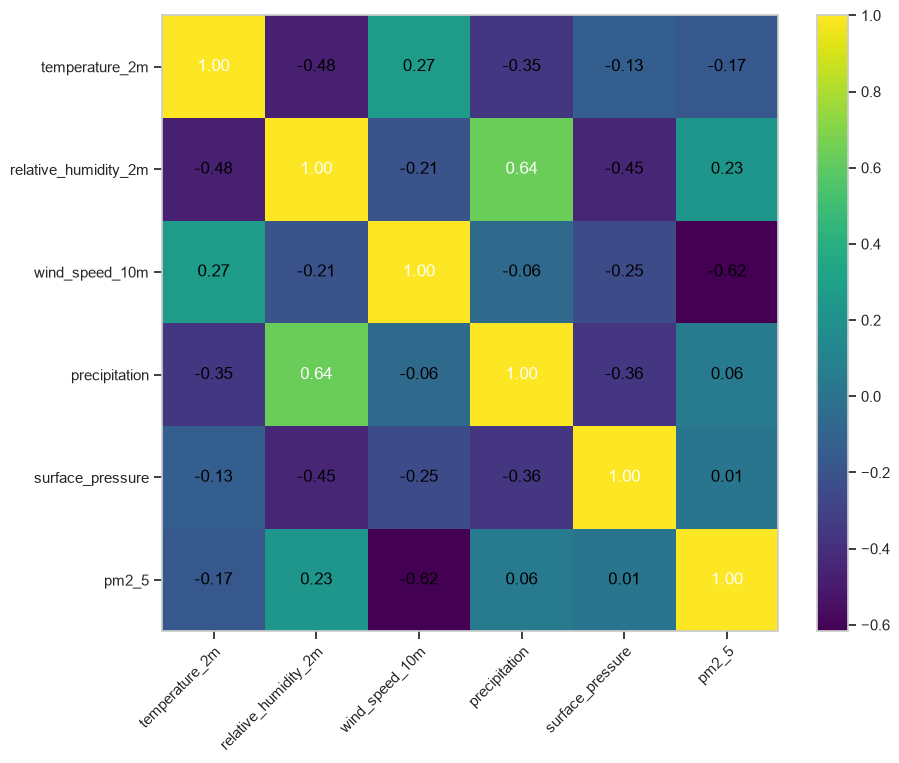

In [9]:
cols_con = ['temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'precipitation', 'surface_pressure', 'pm2_5']
heatmap(df[cols_con].corr().values, row_names=cols_con, column_names=cols_con, figsize=(10, 8))
plt.show()

### Nhận xét heatmap

**Tương quan với `pm2_5` (hàng/cột cuối):**

| Đặc trưng | r | Mức độ | Giải thích |
|---|---|---|---|
| `wind_speed_10m` | −0.62 | Trung bình–mạnh, **ngược chiều** | Gió mạnh khuếch tán và cuốn bụi đi; gió lặng làm bụi tích tụ |
| `relative_humidity_2m` | +0.23 | Yếu | Một phần do mùa (xem 1.3.4) |
| `temperature_2m` | −0.17 | Yếu | Ngày nóng thường đi kèm gió mạnh hơn (r nhiệt độ–gió = +0.27) |
| `precipitation` | +0.06 | Gần 0 | Mưa rửa trôi bụi trong ngày mưa, nhưng trung bình cả ngày gần như không thấy |
| `surface_pressure` | +0.01 | Gần 0 | Không có quan hệ tuyến tính |

**Giữa các đặc trưng:** độ ẩm – lượng mưa (+0.64), độ ẩm – nhiệt độ (−0.48), độ ẩm – áp suất (−0.45) tương quan đáng kể
→ có **đa cộng tuyến** nhẹ; hệ số hồi quy tuyến tính của độ ẩm vì vậy sẽ khó diễn giải.

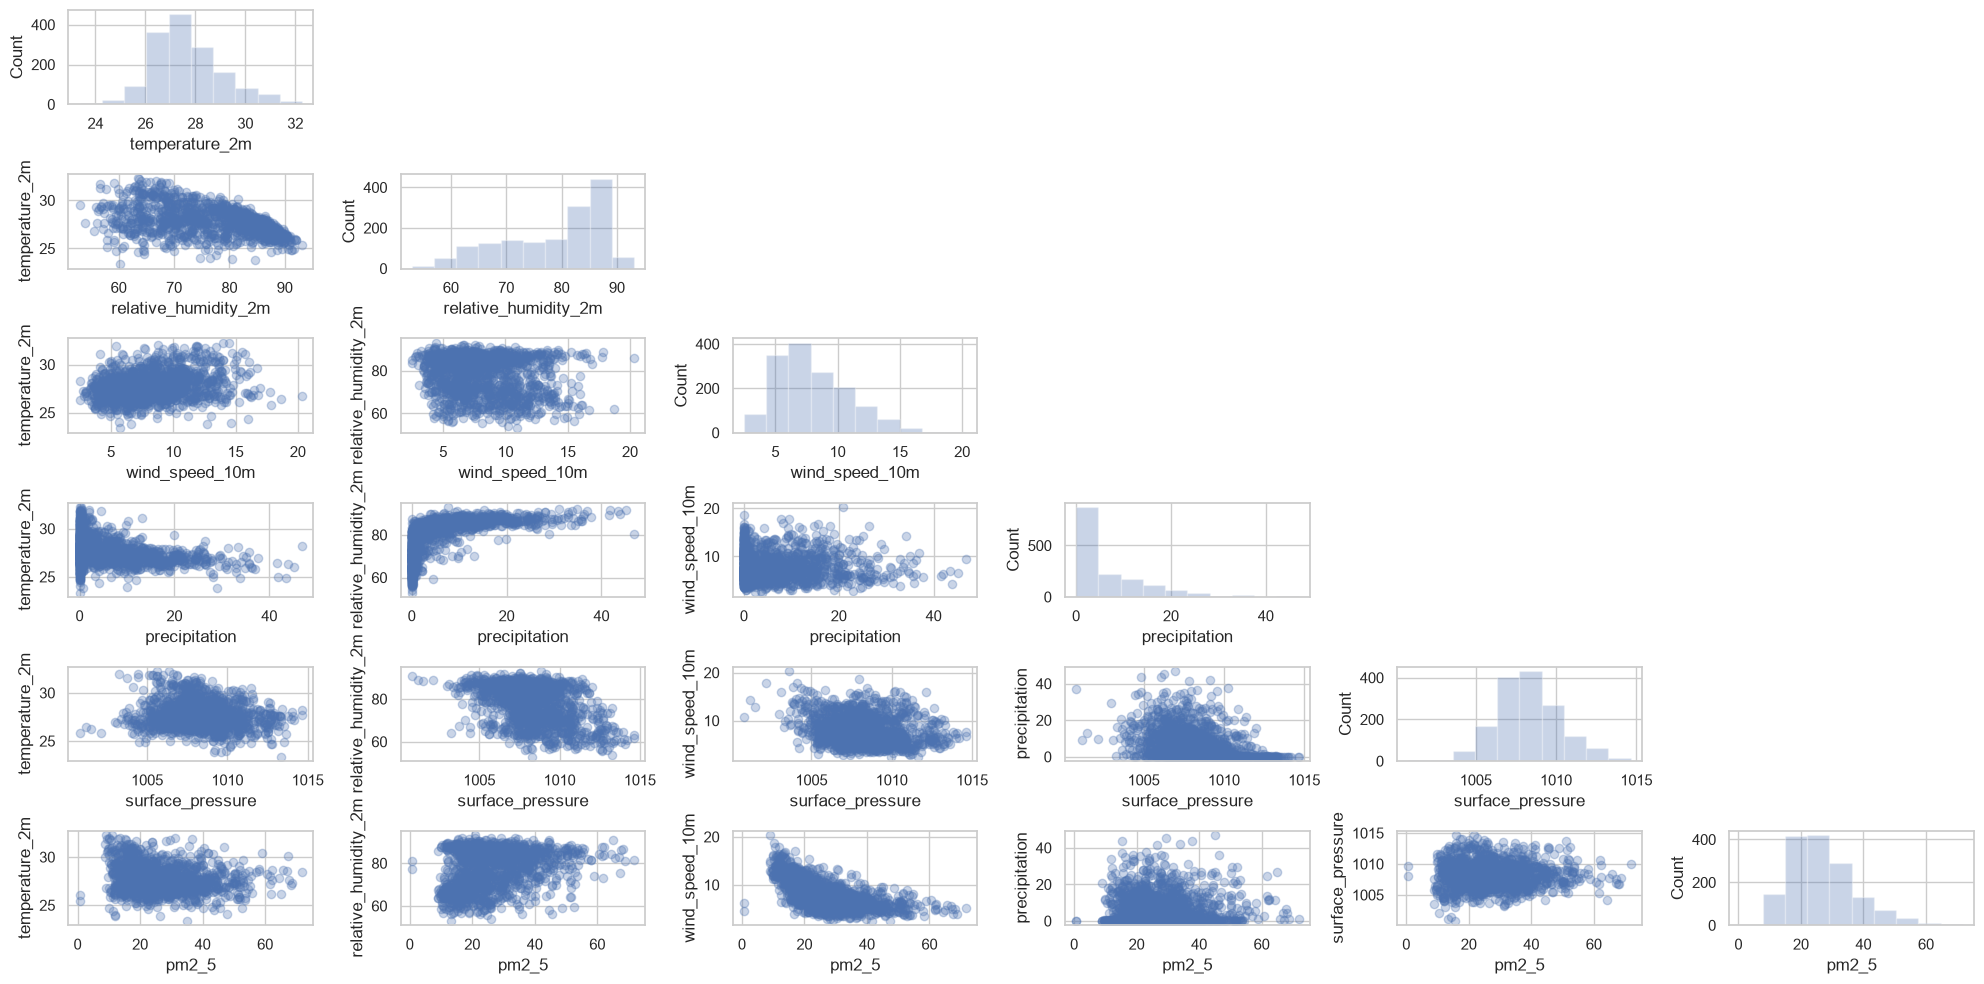

In [10]:
scatterplotmatrix(df[cols_con].values, names=cols_con, figsize=(20, 10), alpha=0.3)
plt.tight_layout()
plt.show()

### 1.3.1 Xếp hạng tương quan với PM2.5: Pearson và Spearman

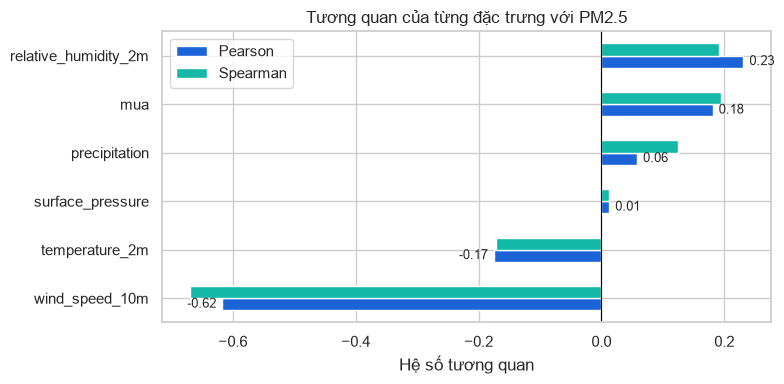

,Pearson,Spearman
wind_speed_10m,-0.617,-0.670
temperature_2m,-0.175,-0.172
surface_pressure,0.012,0.012
precipitation,0.058,0.124
mua,0.181,0.194
relative_humidity_2m,0.231,0.191


In [11]:
corr_p = df.corr()['pm2_5'].drop('pm2_5')
corr_s = df.corr(method='spearman')['pm2_5'].drop('pm2_5')
bang = pd.DataFrame({'Pearson': corr_p, 'Spearman': corr_s}).sort_values('Pearson')

ax = bang.plot.barh(figsize=(8, 4), color=['#1b63d6', '#14b8a6'])
ax.axvline(0, color='black', lw=0.8)
for i, v in enumerate(bang['Pearson']):
    ax.text(v + (0.01 if v >= 0 else -0.01), i - 0.12, f'{v:.2f}', va='center', ha='left' if v >= 0 else 'right', fontsize=9)
ax.set_title('Tương quan của từng đặc trưng với PM2.5')
ax.set_xlabel('Hệ số tương quan')
plt.tight_layout()
plt.show()
bang.round(3)

**Đọc biểu đồ:**

- **Pearson** đo quan hệ *tuyến tính*; **Spearman** đo quan hệ *đơn điệu* (dựa trên thứ hạng, ít bị ngoại lai chi phối).
- Gió có |Spearman| = 0.67 > |Pearson| = 0.62: quan hệ đơn điệu nhưng **cong** — từ gió lặng sang gió nhẹ thì PM2.5 giảm nhanh,
  gió đã mạnh thì tăng thêm cũng giảm ít. Mô hình phi tuyến (cây, đa thức) sẽ khai thác được phần cong này.
- Lượng mưa có Spearman (0.12) gấp đôi Pearson (0.06): phân phối mưa lệch rất mạnh (nhiều ngày 0 mm), Pearson bị vài ngày mưa lớn chi phối.

### 1.3.2 PM2.5 theo tháng trong năm

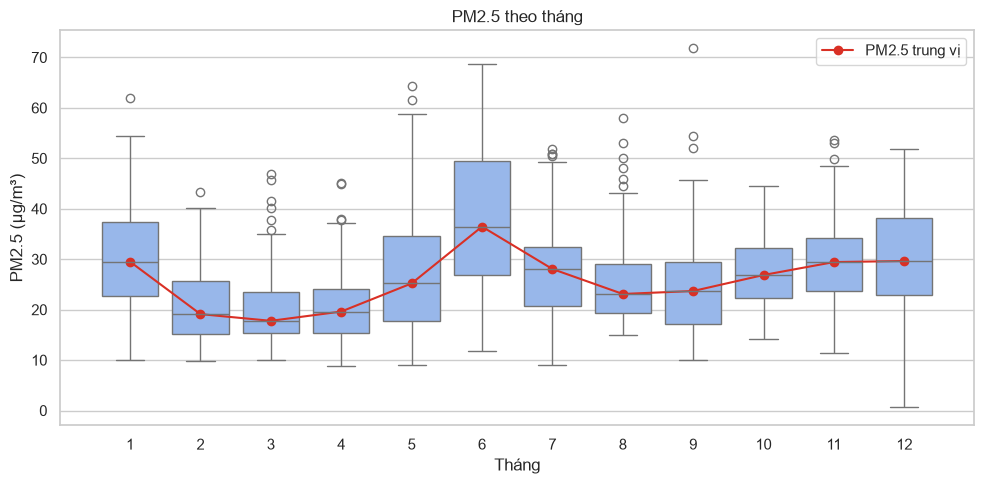

,count,median
date,,
1,124,29.5
2,113,19.1
3,124,17.8
4,120,19.6
5,124,25.2
6,120,36.5
7,124,28.1
8,152,23.1
9,150,23.7


In [12]:
thang = pd.to_datetime(pd.read_csv('data/pm25_hcm_ngay.csv', usecols=['date']).loc[df.index, 'date']).dt.month

plt.figure(figsize=(10, 5))
sns.boxplot(x=thang, y=df['pm2_5'], color='#8ab4f8')
trung_vi = df.groupby(thang)['pm2_5'].median()
plt.plot(range(len(trung_vi)), trung_vi.values, 'o-', color='#d93025', label='PM2.5 trung vị')
plt.title('PM2.5 theo tháng')
plt.xlabel('Tháng')
plt.ylabel('PM2.5 (µg/m³)')
plt.legend()
plt.tight_layout()
plt.show()
df.groupby(thang)['pm2_5'].agg(['count', 'median']).round(1)

**Nhận xét:**

- PM2.5 **thấp nhất vào tháng 2–4** (trung vị 17.8–19.6 µg/m³), trùng với thời kỳ **gió mạnh nhất năm**
  (trung vị gió tháng 3–4 ≈ 10 km/h, so với ≈ 6 km/h tháng 10–1) — khớp với tương quan gió −0.62 ở trên.
- PM2.5 **cao nhất tháng 6** (36.5) và nhóm tháng 11–1 (≈ 29.5). Đỉnh tháng 6 không giải thích được chỉ bằng gió
  (gió tháng 6 ≈ 7.4 km/h, không quá yếu), có thể do bụi/khói vận chuyển từ xa mà mô hình CAMS mô phỏng.
- **Lưu ý trung thực:** đây là số liệu mô hình CAMS (~45 km), chưa đối chiếu trạm mặt đất, nên mẫu hình theo mùa cần kiểm chứng thêm.

### 1.3.3 Gió và PM2.5 — phát hiện ngoại lai

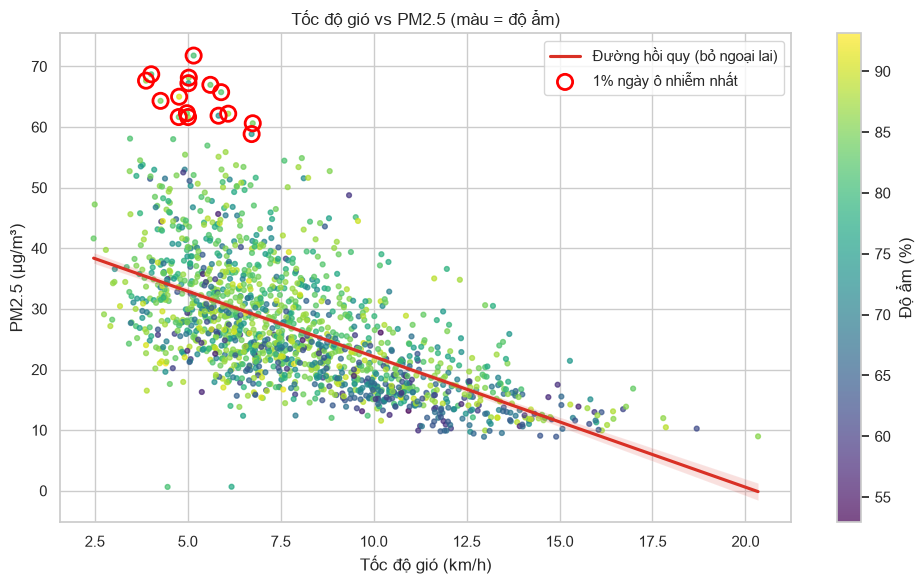

r có ngoại lai   : -0.617
r bỏ ngoại lai   : -0.628


,pm2_5,temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation,surface_pressure,mua
894,61.87,26.20,73.25,5.83,11.6,1010.69,0
1011,61.65,28.02,83.54,4.76,13.6,1005.36,1
1023,64.32,27.83,84.17,4.27,11.5,1004.22,1
1032,65.75,28.67,82.25,5.90,0.9,1008.32,1
1036,60.62,28.21,84.29,6.75,2.6,1007.02,1
1038,61.65,27.20,87.58,5.01,24.5,1006.70,1
1045,62.20,27.62,87.38,6.09,11.9,1007.85,1
1046,66.96,28.60,82.96,5.61,4.5,1006.92,1
1050,67.65,27.60,86.08,3.88,6.5,1006.83,1
1057,65.00,26.18,90.75,4.77,26.6,1007.66,1


In [13]:
ngoai_lai = df['pm2_5'] > df['pm2_5'].quantile(0.99)
plt.figure(figsize=(10, 6))
sc = plt.scatter(df['wind_speed_10m'], df['pm2_5'], c=df['relative_humidity_2m'], cmap='viridis', s=12, alpha=0.7)
plt.colorbar(sc, label='Độ ẩm (%)')
sns.regplot(data=df[~ngoai_lai], x='wind_speed_10m', y='pm2_5', scatter=False, color='#d93025', label='Đường hồi quy (bỏ ngoại lai)')
plt.scatter(df.loc[ngoai_lai, 'wind_speed_10m'], df.loc[ngoai_lai, 'pm2_5'], s=120, facecolors='none', edgecolors='red', lw=2, label='1% ngày ô nhiễm nhất')
plt.title('Tốc độ gió vs PM2.5 (màu = độ ẩm)')
plt.xlabel('Tốc độ gió (km/h)')
plt.ylabel('PM2.5 (µg/m³)')
plt.legend()
plt.tight_layout()
plt.show()

print('r có ngoại lai   :', round(df['wind_speed_10m'].corr(df['pm2_5']), 3))
print('r bỏ ngoại lai   :', round(df.loc[~ngoai_lai, 'wind_speed_10m'].corr(df.loc[~ngoai_lai, 'pm2_5']), 3))
df[ngoai_lai]

**Nhận xét:**

- Xu hướng rõ: **gió càng mạnh, PM2.5 càng thấp** (r = −0.62). Bỏ 1% ngày ô nhiễm nhất thì r = −0.63 → ngoại lai không làm sai lệch quan hệ.
- Các ngày ô nhiễm nhất (PM2.5 > 58.6 µg/m³, vòng đỏ) đều có **gió yếu (≈ 4–7 km/h) và độ ẩm cao** (màu vàng–xanh lá):
  điều kiện khí quyển ổn định, bụi không khuếch tán được.

### 1.3.4 Độ ẩm cao thì bụi cũng cao? — biến gây nhiễu là mùa

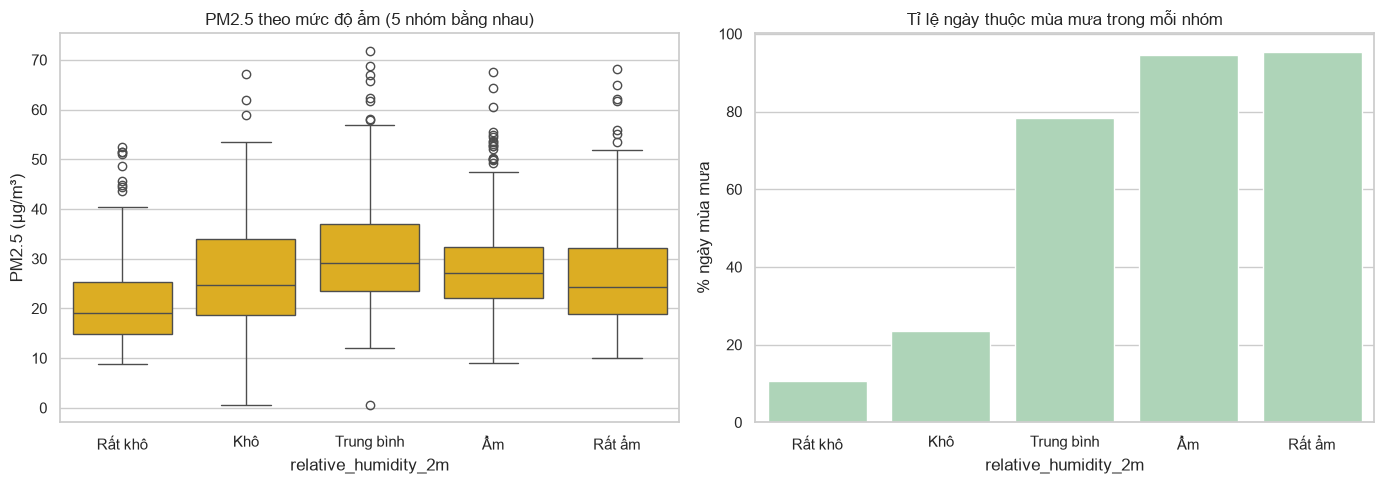

corr(độ ẩm, PM2.5)      = 0.231
corr(mùa mưa, độ ẩm)    = 0.712
corr(mùa mưa, PM2.5)    = 0.181


In [14]:
muc_am = pd.qcut(df['relative_humidity_2m'], 5, labels=['Rất khô', 'Khô', 'Trung bình', 'Ẩm', 'Rất ẩm'])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x=muc_am, y=df['pm2_5'], color='#fbbc04', ax=ax[0])
ax[0].set_title('PM2.5 theo mức độ ẩm (5 nhóm bằng nhau)')
ax[0].set_ylabel('PM2.5 (µg/m³)')
sns.barplot(x=muc_am, y=df['mua'] * 100, color='#a8dab5', errorbar=None, ax=ax[1])
ax[1].set_title('Tỉ lệ ngày thuộc mùa mưa trong mỗi nhóm')
ax[1].set_ylabel('% ngày mùa mưa')
plt.tight_layout()
plt.show()

print('corr(độ ẩm, PM2.5)      =', round(df['relative_humidity_2m'].corr(df['pm2_5']), 3))
print('corr(mùa mưa, độ ẩm)    =', round(df['mua'].corr(df['relative_humidity_2m']), 3))
print('corr(mùa mưa, PM2.5)    =', round(df['mua'].corr(df['pm2_5']), 3))

**Giải thích — biến gây nhiễu (*confounding variable*) là mùa:**
- Độ ẩm tương quan dương với PM2.5 (r = +0.23), nhưng độ ẩm gắn rất chặt với mùa mưa (r = +0.71), và mùa mưa ở số liệu này
  có PM2.5 cao hơn (r = +0.18). Biểu đồ phải cho thấy nhóm "Rất ẩm" gần như toàn là ngày mùa mưa.
- Khi đưa đồng thời gió, mùa và các biến khác vào hồi quy tuyến tính (mục 1.5), hệ số chuẩn hóa của độ ẩm chỉ còn ≈ −0.2 µg/m³
  — tức là **phần lớn tương quan +0.23 là gián tiếp qua mùa và gió**, không phải độ ẩm trực tiếp làm tăng bụi.

### 1.3.5 Mùa mưa / mùa khô (`mua`) và phân phối PM2.5

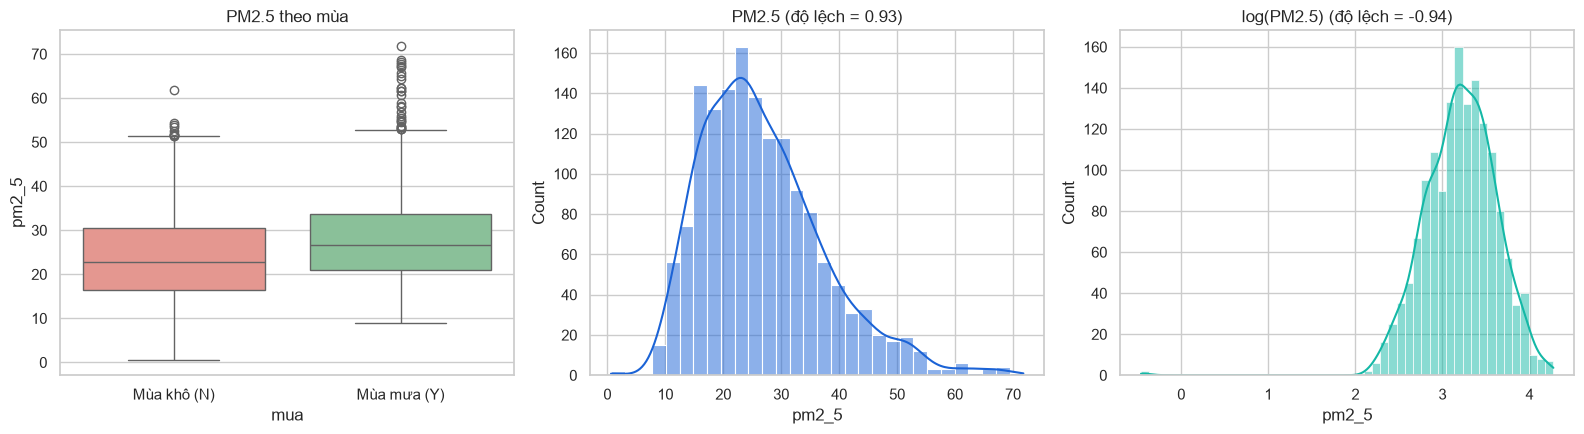

,count,median
mua,,
0,605,22.740
1,924,26.665


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=df, x='mua', y='pm2_5', hue='mua', palette=['#f28b82', '#81c995'], legend=False, ax=ax[0])
ax[0].set_xticks([0, 1], ['Mùa khô (N)', 'Mùa mưa (Y)'])
ax[0].set_title('PM2.5 theo mùa')
sns.histplot(df['pm2_5'], kde=True, ax=ax[1], color='#1b63d6')
ax[1].set_title(f"PM2.5 (độ lệch = {df['pm2_5'].skew():.2f})")
sns.histplot(np.log(df['pm2_5']), kde=True, ax=ax[2], color='#14b8a6')
ax[2].set_title(f"log(PM2.5) (độ lệch = {np.log(df['pm2_5']).skew():.2f})")
plt.tight_layout()
plt.show()
df.groupby('mua')['pm2_5'].agg(['count', 'median'])

**Nhận xét:**

- Mùa mưa (924 ngày) có PM2.5 trung vị **26.7 µg/m³**, mùa khô (605 ngày) **22.7 µg/m³** — ngược với nhận định thường gặp
  "mùa khô ô nhiễm hơn". Nguyên nhân chính là tháng 2–4 mùa khô có gió rất mạnh (mục 1.3.2). Đây là số liệu CAMS, cần đối chiếu trạm thật.
- PM2.5 **lệch phải** (độ lệch 0.93): đa số ngày 15–35 µg/m³, một số ít ngày rất cao. Lấy log làm lệch sang trái (−0.94)
  do vài ngày PM2.5 rất thấp (thấp nhất 0.63) → biến đổi log **không** cần thiết cho dữ liệu này.

# 1.4 Build model

> Giữ nguyên cách chia của bài Lab (`train_test_split` ngẫu nhiên). Với chuỗi thời gian, các ngày liền kề rất giống nhau
> nên chia ngẫu nhiên cho điểm hơi lạc quan; mô hình dự báo thật của hệ thống (`ml/train_model.py`) chia **theo thời gian**.

In [16]:
X = df.drop(columns='pm2_5')
y = df['pm2_5']
# random_state cố định để kết quả chạy lại giống nhau
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1146, 6), (383, 6), (1146,), (383,))

In [17]:
lg = LinearRegression()
lg.fit(X_train, y_train)
lg.score(X_train, y_train), lg.score(X_test, y_test)

(0.405435161331984, 0.44595504172248346)

## 1.5 Feature importance

In [18]:
df_imp = pd.DataFrame({
    'importances': lg.coef_,
    'features': lg.feature_names_in_
}).sort_values(by='importances')
df_imp

,importances,features
2,-2.391880,wind_speed_10m
4,-0.542303,surface_pressure
0,-0.397360,temperature_2m
3,-0.153680,precipitation
1,-0.022356,relative_humidity_2m
5,3.180665,mua


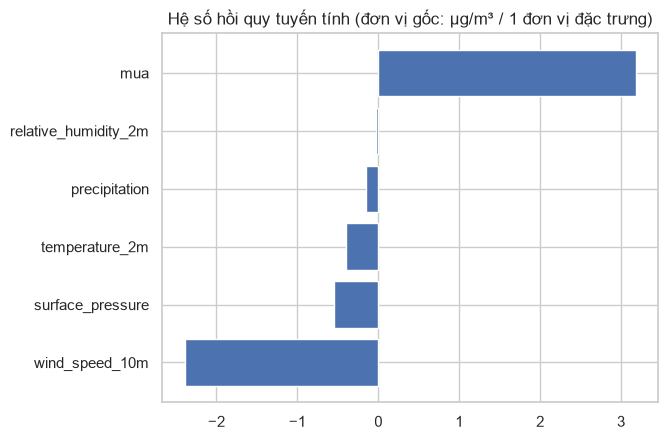

In [19]:
plt.barh(y=df_imp['features'], width=df_imp['importances'])
plt.title('Hệ số hồi quy tuyến tính (đơn vị gốc: µg/m³ / 1 đơn vị đặc trưng)')
plt.show()

**Lưu ý khi đọc biểu đồ trên:** hệ số là mức thay đổi PM2.5 khi đặc trưng tăng **1 đơn vị gốc** (1 °C, 1 %, 1 hPa...), nên không so sánh trực tiếp được giữa các đặc trưng khác đơn vị. Biểu đồ dưới chuẩn hóa để so sánh công bằng.

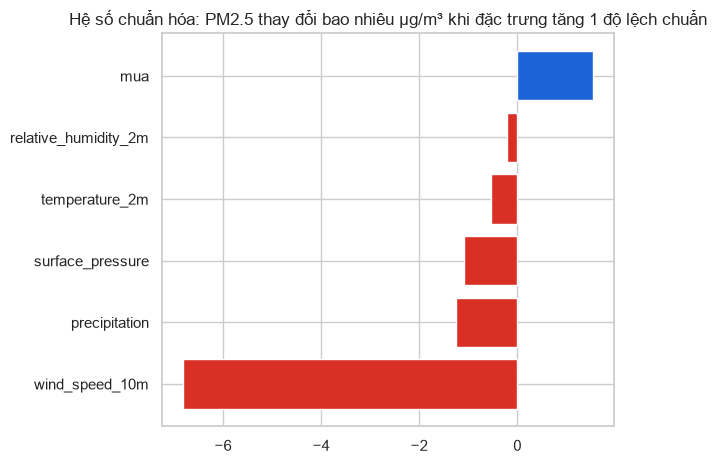

wind_speed_10m         -6.82
precipitation          -1.24
surface_pressure       -1.08
temperature_2m         -0.54
relative_humidity_2m   -0.20
mua                     1.55
dtype: float64

In [20]:
scaler = StandardScaler()
lg_std = LinearRegression().fit(scaler.fit_transform(X_train), y_train)
he_so_chuan = pd.Series(lg_std.coef_, index=X_train.columns).sort_values()

colors = ['#d93025' if v < 0 else '#1b63d6' for v in he_so_chuan]
plt.barh(he_so_chuan.index, he_so_chuan.values, color=colors)
plt.title('Hệ số chuẩn hóa: PM2.5 thay đổi bao nhiêu µg/m³ khi đặc trưng tăng 1 độ lệch chuẩn')
plt.tight_layout()
plt.show()
he_so_chuan.round(2)

## Linear Regression with Polynomial

In [21]:
pf = PolynomialFeatures(degree=2)
X_train_pf = pf.fit_transform(X_train)
X_test_pf = pf.transform(X_test)

lg_pf = LinearRegression()
lg_pf.fit(X_train_pf, y_train)
lg_pf.score(X_train_pf, y_train), lg_pf.score(X_test_pf, y_test)

(0.4514084713803198, 0.4965210977374208)

## Build model non-linear

In [22]:
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
dt.score(X_train, y_train), dt.score(X_test, y_test)   # train ≈ 1.0 nhưng test thấp hơn nhiều -> overfitting

(1.0, -0.13979399447829666)

In [23]:
grid = GridSearchCV(estimator=DecisionTreeRegressor(random_state=42), param_grid={
    'max_depth': [4, 5, 6, 7],
    'min_samples_split': [2, 3, 4],
    'min_samples_leaf': [1, 2, 3, 4]
})
grid.fit(X_train, y_train)
grid.best_score_, grid.best_params_

(np.float64(0.36965184698645825),
 {'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2})

In [24]:
dt = DecisionTreeRegressor(**grid.best_params_, random_state=42)
dt.fit(X_train, y_train)
dt.score(X_train, y_train), dt.score(X_test, y_test)

(0.5009797363322874, 0.40278274285999727)

In [25]:
grid_rf = GridSearchCV(estimator=RandomForestRegressor(random_state=42), param_grid={
    'max_depth': [6, 8, 10],
    'min_samples_split': [2, 4],
    'min_samples_leaf': [1, 2, 4]
}, n_jobs=-1)
grid_rf.fit(X_train, y_train)
grid_rf.best_score_, grid_rf.best_params_

(np.float64(0.40971398710160506),
 {'max_depth': 6, 'min_samples_leaf': 4, 'min_samples_split': 2})

In [26]:
rf = RandomForestRegressor(**grid_rf.best_params_, random_state=42)
rf.fit(X_train, y_train)
rf.score(X_train, y_train), rf.score(X_test, y_test)

(0.5884371626481116, 0.4543849796845352)

In [27]:
adaboost = AdaBoostRegressor(random_state=42)
adaboost.fit(X_train, y_train)
adaboost.score(X_train, y_train), adaboost.score(X_test, y_test)

(0.37656942911701297, 0.2730216409236982)

In [28]:
hist = HistGradientBoostingRegressor(random_state=42)
hist.fit(X_train, y_train)
hist.score(X_train, y_train), hist.score(X_test, y_test)

(0.8727302042991988, 0.35522469100334886)

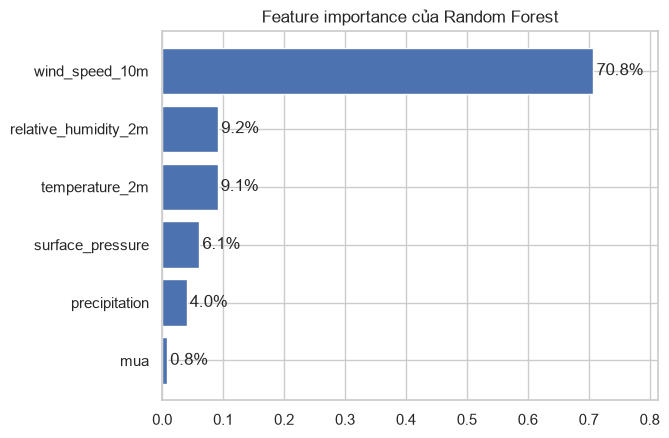

,features,importances
5,mua,0.008034
3,precipitation,0.040250
4,surface_pressure,0.061005
0,temperature_2m,0.091074
1,relative_humidity_2m,0.091804
2,wind_speed_10m,0.707834


In [29]:
df_imp = pd.DataFrame({
    'features': rf.feature_names_in_,
    'importances': rf.feature_importances_
}).sort_values(by='importances')

plt.barh(y=df_imp['features'], width=df_imp['importances'])
for i, v in enumerate(df_imp['importances']):
    plt.text(v + 0.005, i, f'{v:.1%}', va='center')
plt.title('Feature importance của Random Forest')
plt.xlim(0, df_imp['importances'].max() * 1.15)
plt.show()
df_imp

**Nhận xét:**

Random Forest dồn **≈ 71%** độ quan trọng cho **tốc độ gió**; độ ẩm (9.2%), nhiệt độ (9.1%), áp suất (6.1%), mưa (4.0%) đứng sau,
còn `mua` gần như bằng 0 (0.8%) vì thông tin mùa đã nằm sẵn trong độ ẩm và gió. Kết quả khớp với heatmap: gió là yếu tố thời tiết
quyết định PM2.5 ở TP.HCM.

## 1.6. Validation

In [30]:
# Mỗi mô hình dự đoán bằng CHÍNH NÓ
models = {
    'Linear Regression': (lg, X_test),
    'Polynomial (bậc 2)': (lg_pf, X_test_pf),
    'Decision Tree': (dt, X_test),
    'Random Forest': (rf, X_test),
    'AdaBoost': (adaboost, X_test),
    'Hist Gradient Boosting': (hist, X_test),
}
data_validation = []
du_doan = {}
for ten, (model, X_t) in models.items():
    y_test_pred = model.predict(X_t)
    du_doan[ten] = y_test_pred
    data_validation.append({
        'model': ten,
        'MAE': mean_absolute_error(y_test, y_test_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'R2': r2_score(y_test, y_test_pred),
    })
df_validation = pd.DataFrame(data_validation).sort_values('R2', ascending=False).reset_index(drop=True)
df_validation.round(3)

,model,MAE,RMSE,R2
0,Polynomial (bậc 2),5.175,6.845,0.497
1,Random Forest,5.375,7.126,0.454
2,Linear Regression,5.577,7.181,0.446
3,Decision Tree,5.637,7.455,0.403
4,Hist Gradient Boosting,5.796,7.747,0.355
5,AdaBoost,6.674,8.226,0.273


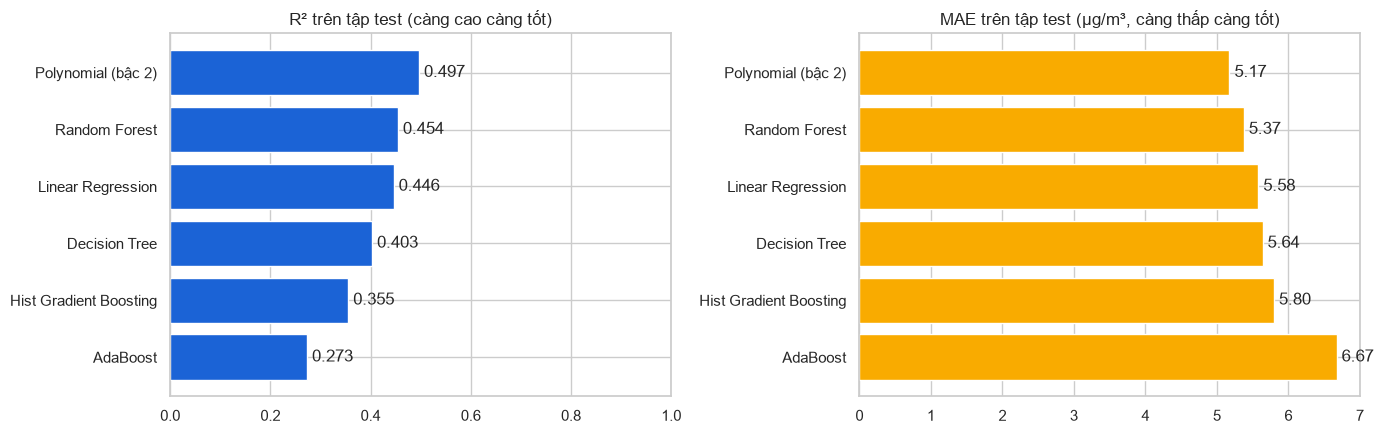

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
dv = df_validation.sort_values('R2')
ax[0].barh(dv['model'], dv['R2'], color='#1b63d6')
ax[0].set_xlim(min(0, dv['R2'].min() - 0.05), 1)
ax[0].set_title('R² trên tập test (càng cao càng tốt)')
ax[1].barh(dv['model'], dv['MAE'], color='#f9ab00')
ax[1].set_title('MAE trên tập test (µg/m³, càng thấp càng tốt)')
for a, cot, fmt in ((ax[0], 'R2', '{:.3f}'), (ax[1], 'MAE', '{:,.2f}')):
    for i, v in enumerate(dv[cot]):
        a.text(v, i, ' ' + fmt.format(v), va='center')
plt.tight_layout()
plt.show()

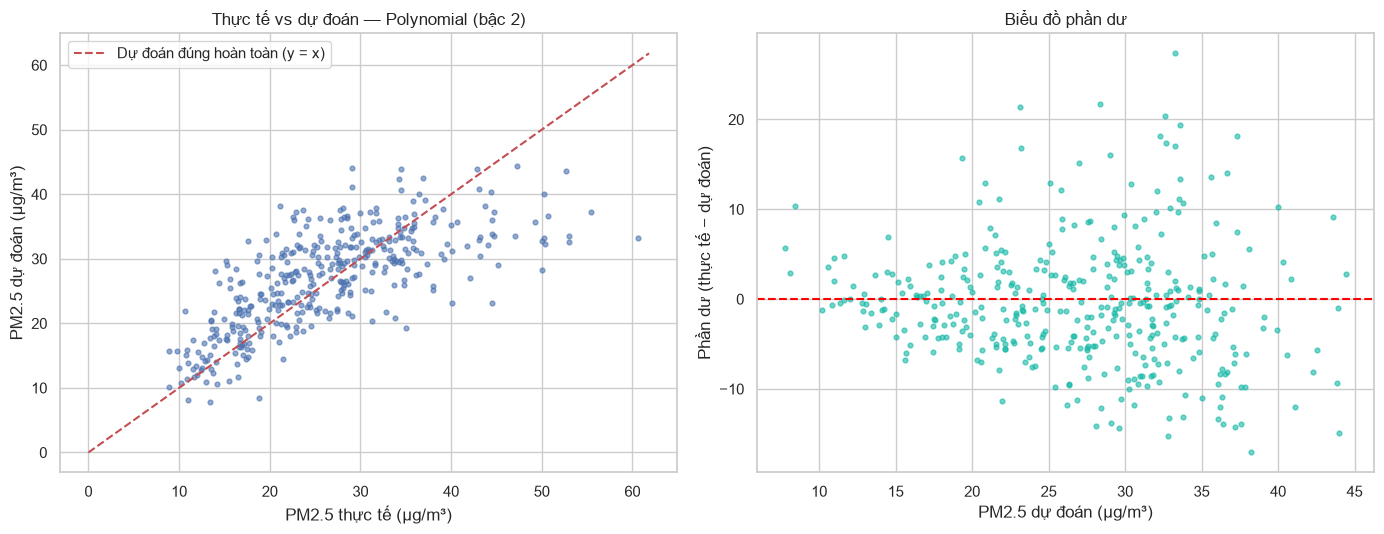

In [32]:
tot_nhat = df_validation.loc[0, 'model']
y_pred = du_doan[tot_nhat]

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ax[0].scatter(y_test, y_pred, s=12, alpha=0.6)
lim = [0, max(y_test.max(), y_pred.max()) * 1.02]
ax[0].plot(lim, lim, 'r--', label='Dự đoán đúng hoàn toàn (y = x)')
ax[0].set_xlabel('PM2.5 thực tế (µg/m³)')
ax[0].set_ylabel('PM2.5 dự đoán (µg/m³)')
ax[0].set_title(f'Thực tế vs dự đoán — {tot_nhat}')
ax[0].legend()

phan_du = y_test - y_pred
ax[1].scatter(y_pred, phan_du, s=12, alpha=0.6, color='#14b8a6')
ax[1].axhline(0, color='red', ls='--')
ax[1].set_xlabel('PM2.5 dự đoán (µg/m³)')
ax[1].set_ylabel('Phần dư (thực tế − dự đoán)')
ax[1].set_title('Biểu đồ phần dư')
plt.tight_layout()
plt.show()

In [33]:
# Lưu chỉ số cho trang Phương pháp của web (ml/notebooks/xuat_bieu_do.py đọc tệp này)
import json
Path('ket_qua').mkdir(exist_ok=True)
json.dump({'so_ngay': int(len(df)), 'mo_hinh': df_validation.round(4).to_dict('records')},
          open('ket_qua/lab01_chi_so.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)

### Kết luận

1. **Tương quan:** tốc độ gió là yếu tố mạnh nhất (r = −0.62, chiếm ≈ 71% độ quan trọng của Random Forest); các biến thời tiết khác yếu.
   Độ ẩm có tương quan dương nhưng phần lớn là gián tiếp qua mùa (biến gây nhiễu).
2. **Mô hình:** tốt nhất là **hồi quy đa thức bậc 2** (R² = 0.497, MAE = 5.17 µg/m³), tiếp theo Random Forest (0.454) và hồi quy tuyến tính (0.446).
   Cây quyết định không giới hạn độ sâu **quá khớp** (train R² = 1.0, test R² = −0.14); GridSearch đưa test R² lên 0.40.
3. **Giới hạn:** chỉ dùng thời tiết cùng ngày thì giải thích được khoảng **một nửa** biến động PM2.5; phần còn lại do nguồn thải
   (giao thông, công nghiệp, đốt sinh khối) và bụi vận chuyển từ xa — không có trong dữ liệu. Chia ngẫu nhiên (theo bài Lab) cho điểm hơi lạc quan
   với chuỗi thời gian; mô hình chạy thật của hệ thống được đánh giá bằng cách chia theo thời gian.